# SPAM or HAM -- a spam e-mail classifier built from scratch

**Task.** Build a classifier that reads a folder `test/` of e-mails (`email.txt`, `email1.txt`, ...) and outputs
`+1` (spam) or `0` (not spam) for each of them. No training data is supplied, so I assembled it from public corpora.
All learning algorithms (sparse matrices, TF-IDF, Naive Bayes, Logistic Regression, linear SVM, cross-validation,
metrics) are implemented from scratch with `numpy` in `spam_lib.py`; `matplotlib` is used only for plots.

**Files**

| file | purpose |
|---|---|
| `spam_lib.py` | all from-scratch code: e-mail parsing, features, CSR matrix, NB, LR, SVM, CV, metrics |
| `experiments.py` | the experimental pipeline that this notebook runs stage by stage |
| `classify.py` | **`predict_folder('test')`** -- the required prediction function |
| `model/spam_model.npz` | trained parameters (so no training at prediction time) |
| `Spam_or_Ham.ipynb` / `.pdf` | this notebook (executed) |
| `Report.odg` / `Report.pdf` | the written report |

The notebook is organised as: data -> preprocessing -> exploration -> algorithms -> model selection ->
held-out test -> robustness to distribution shift -> final model.

In [1]:
import os, sys, json, inspect
assert os.path.exists('spam_lib.py'), 'start Jupyter from the project folder (the one containing spam_lib.py)'
sys.path.insert(0, os.getcwd())
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display
import experiments as E
import spam_lib as L

def show(name, width=640):
    display(Image(filename=os.path.join(E.FIG, name), width=width))

print('working directory:', os.getcwd())

working directory: /home/claude/spam_project


## 1. Data

No labelled data was provided, so I used **publicly available** corpora (no private data, no scraping):

| corpus | content | size used | how obtained |
|---|---|---|---|
| **SpamAssassin public corpus** | raw RFC-822 e-mails 2002-03: `easy-ham-1/2`, `hard-ham-1`, `spam-1/2` | 6046 | npm package `@stdlib/dist-datasets-spam-assassin` (Apache-2.0 packaging of the public corpus) |
| **Enron-Spam, "enron1"** (Metsis et al. 2006) | corporate ham from Enron employees + honeypot spam, pre-tokenised lower-case text | 5171 | `spam_ham_dataset.csv` from GitHub repo `MSc-AI/SpamEmail` |
| **SMS Spam Collection** (Almeida et al.) | short text messages | 5574 | `sms.tsv` from GitHub `justmarkham/pycon-2016-tutorial` |

Why two e-mail corpora? They have *very* different ham and spam (mailing-list technical chatter versus corporate gas-pipeline
business mail; 2002 raw MIME versus pre-tokenised text). A classifier trained on one alone learns that corpus's
vocabulary (we measure this in Section 7), so the final model is trained on both. The SMS corpus is evaluated
as an optional extra training source (Section 7) and is used only if it does not hurt e-mail accuracy.

**Exact duplicates** (identical subject+body tokens) are removed before splitting, otherwise copies of the same
message would land in both train and test and inflate the accuracy.

In [2]:
S = E.stage_data()

SpamAssassin:  5850 e-mails kept  (ham 4091, spam 1759, spam fraction 0.301)
Enron-1     :  4639 e-mails kept  (ham 3184, spam 1455, spam fraction 0.314)
raw e-mails 11217 -> 10489 after removing 728 exact duplicates
SMS Spam Collection: 5089 unique texts (ham 4494, spam 595)
parsed in 14.1s


## 2. From a raw e-mail to features

Choices (all implemented in `spam_lib.parse_email / featurise_email / Vectorizer`):

1. **Use only Subject + body.** Transport headers (`Received:`, `Delivered-To:` ...) describe *how the corpus was
   collected*, not whether a message is spam. I verify below that a model that sees *only* those headers already
   reaches ~96 % on a random split -- a leak that collapses under temporal shift -- so headers are discarded.
   Files with no headers at all (just a body) are handled as well.
2. **MIME handling**: `text/plain` parts are preferred; otherwise `text/html` is converted to text (scripts/styles removed,
   entities decoded, `href` targets counted).  Attachments are ignored.
3. **Mailing-list boiler-plate removal** (`listinfo`, "mailing list", long `____` rules) -- footers added by the lists that
   happen to be in the corpus; they say nothing about spam.
4. **Normalisation** into placeholder tokens: URLs -> `urltoken`, e-mail addresses -> `emailtoken`, currency amounts -> `moneytoken`,
   other numbers -> `numtoken`.  Pre-tokenised text such as `http : / / www . x . com`, `john @ x . com`, `don ' t` is repaired first so that both corpora map to
   the *same* tokens.
5. **Tokens**: lower-case words, small stop-word list removed, subject words kept separately with prefix `s_`.
6. **Features**: bag of unigrams **and adjacent bigrams**, vocabulary built on training data only (document frequency >= 3, top
   `max_features` terms). Naive Bayes uses (binary) counts; LR/SVM use **TF-IDF** with sub-linear tf `1+ln(count)`,
   `idf = ln((1+n)/(1+df))+1` and L2 row normalisation.
7. Nine cheap *style* features (log length, upper-case ratio, "!" count, ...) were also built and are tested in an ablation (Section 5).

In [3]:
# --- demonstration on two real messages ---------------------------------------------------------
i_sa  = int(np.where(S['groups'] == 'spam-1')[0][0])
i_en  = int(np.where(S['groups'] == 'enron1-ham')[0][0])
for name, i in (('SpamAssassin spam', i_sa), ('Enron ham', i_en)):
    raw = S['raws'][i]
    subj, body, nurl = L.parse_email(raw)
    bt, st, sty = L.featurise_email(raw)
    print('=' * 100); print(name, '| raw length', len(raw), 'chars')
    print('--- first 6 raw lines:'); print('\n'.join(raw.split('\n')[:6]))
    print('--- parsed subject :', subj)
    print('--- body (first 200 chars):', ' '.join(body.split())[:200])
    print('--- subject tokens :', st)
    print('--- body tokens    :', bt[:25], '...')
    print('--- bigram terms   :', L.terms_from_tokens(bt, st, 2)[len(bt):len(bt)+6], '...')

SpamAssassin spam | raw length 4928 chars
--- first 6 raw lines:
From 12a1mailbot1@web.de  Thu Aug 22 13:17:22 2002
Return-Path: <12a1mailbot1@web.de>
Delivered-To: zzzz@localhost.spamassassin.taint.org
Received: from localhost (localhost [127.0.0.1])
	by phobos.labs.spamassassin.taint.org (Postfix) with ESMTP id 136B943C32
	for <zzzz@localhost>; Thu, 22 Aug 2002 08:17:21 -0400 (EDT)
--- parsed subject : Life Insurance - Why Pay More?
--- body (first 200 chars): Save up to 70% on Life Insurance. Why Spend More Than You Have To? Life Quote Savings Ensuring your family's financial security is very important. Life Quote Savings makes buying life insurance simple
--- subject tokens : ['life', 'insurance', 'why', 'pay', 'more']
--- body tokens    : ['save', 'numtoken', 'life', 'insurance', 'why', 'spend', 'more', 'life', 'quote', 'savings', 'ensuring', "family's", 'financial', 'security', 'important', 'life', 'quote', 'savings', 'makes', 'buying', 'life', 'insurance', 'simple', 'affordable'

In [4]:
# --- the normaliser repairs pre-tokenised text so both corpora share one vocabulary ---------------
t = "Subject: re : offer\nvisit http : / / www . cheap - pills . com / buy now , mail john @ x . com . it ' s $ 1 , 000 !!"
print(L.featurise_email(t)[:2])
print(L.featurise_email("Visit http://www.cheap-pills.com/buy now, mail john@x.com. It's $1,000 !!")[:2])

(['visit', 'urltoken', 'now', 'mail', 'emailtoken', "it's", 'moneytoken'], ['re', 'offer'])
(['visit', 'urltoken', 'now', 'mail', 'emailtoken', "it's", 'moneytoken'], [])


## 3. Exploratory analysis

Mean of the stylistic features (raw scale):
  feature                   ham       spam
  log_len                 6.582      6.773
  upper_ratio             0.035      0.071
  caps_words              0.013      0.044
  log_exclam              0.280      1.125
  log_money               0.105      0.457
  log_urls                0.435      0.591
  digit_ratio             0.046      0.023
  subj_upper_ratio        0.097      0.142
  log_qmark               0.504      0.446
Median body tokens: ham 78, spam 87;  empty bodies: 8


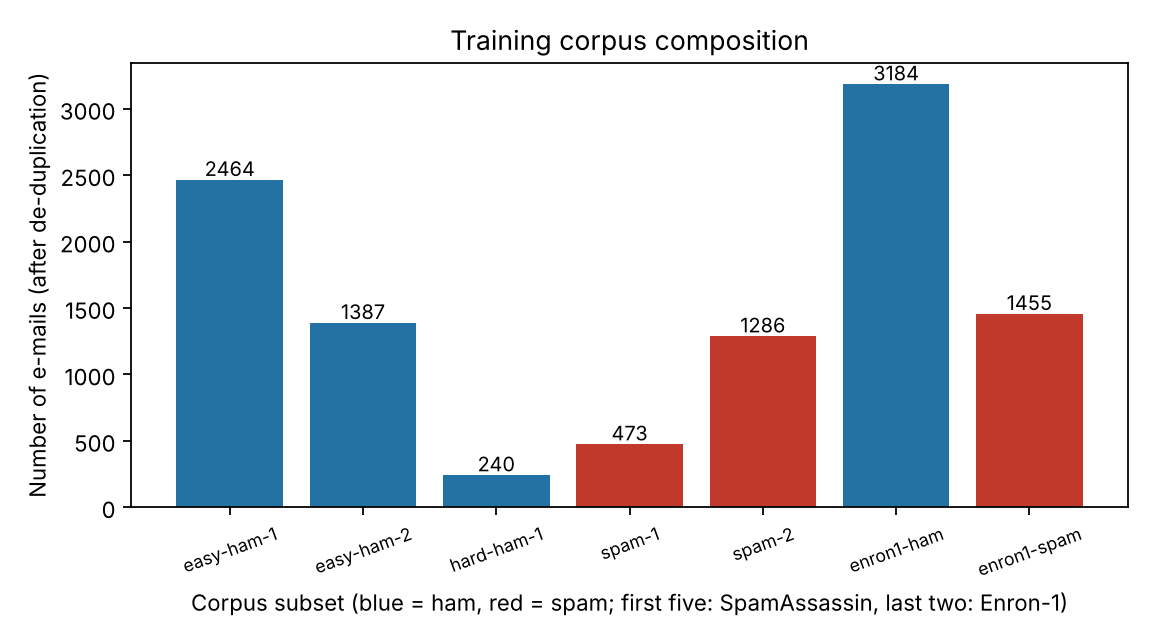

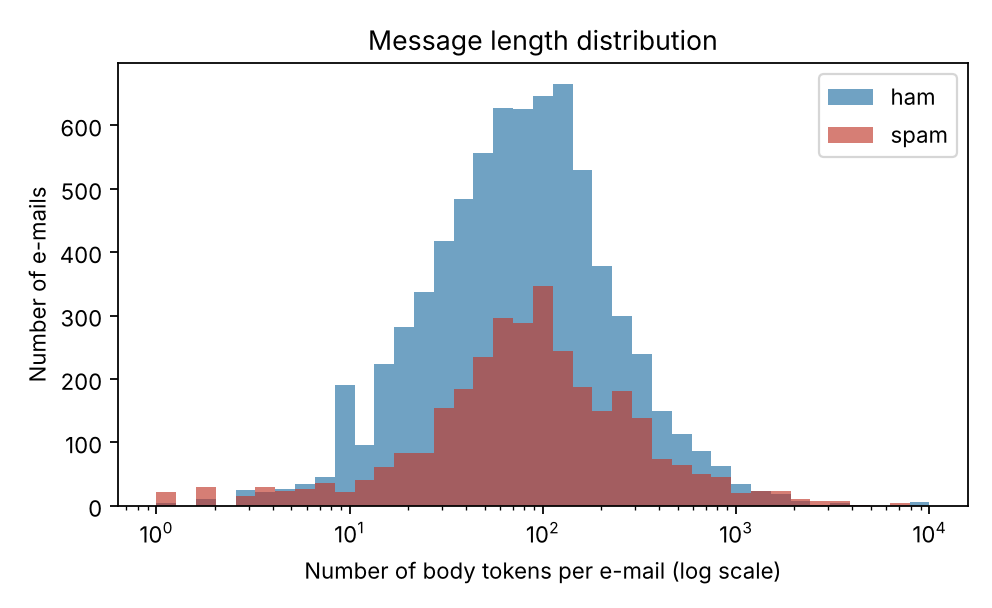

In [5]:
S = E.stage_eda(S)
show('fig1_class_distribution.png'); show('fig2_length_hist.png')

## 4. The algorithms (all written from scratch)

Let `x` be a document's feature vector, `y in {0,1}` its label (1 = spam), `t = 2y-1`.

**Multinomial Naive Bayes** with Laplace smoothing `alpha`:
$\theta_{cj} = \dfrac{N_{cj}+\alpha}{\sum_k N_{ck} + \alpha V}$, and the spam score is
$\log\dfrac{P(1\mid x)}{P(0\mid x)} = \log\dfrac{\pi_1}{\pi_0} + \sum_j x_j\,(\log\theta_{1j}-\log\theta_{0j})$.
Features are binarised (presence/absence) and the class prior is set to 1/2 (see Section 5/7 for why).

**L2-regularised logistic regression**:
$\min_{w,b}\;\sum_i s_i\log\!\big(1+e^{-t_i(w\cdot x_i+b)}\big)+\dfrac{\lambda}{2}\lVert w\rVert^2$,
gradient $\nabla_w = X^\top\!\big[(\sigma(z)-y)\odot s\big]+\lambda w$ with $z=Xw+b$.

**L2 linear SVM** (squared hinge): $\min_{w,b}\;\sum_i s_i\max(0,1-t_i z_i)^2+\dfrac{\lambda}{2}\lVert w\rVert^2$,
gradient $\nabla_w=-2X^\top\!\big[t\odot\max(0,1-tz)\odot s\big]+\lambda w$.

Here $s_i$ are normalised **class-balancing sample weights** (each class contributes equally, which makes the decision
threshold independent of the spam proportion in the training data). Both linear models are trained by full-batch
**Adam** (lr 0.1, 300 iterations); the bias is not regularised. All matrix products use my own **CSR sparse matrix**
(`bincount`-based mat-vec and transposed mat-vec) because the data are about 10^4 documents x 4x10^4 features.

**Final decision**: majority vote of the three classifiers (Section 5 compares this with the single models).

In [6]:
print(inspect.getsource(L.NaiveBayes))
print(inspect.getsource(L.train_linear_model))

class NaiveBayes:
    """Multinomial Naive Bayes, Laplace/Lidstone smoothing alpha, optional binary features."""

    def __init__(self, alpha=0.1, binary=True, balanced_prior=True):
        self.alpha, self.binary, self.balanced_prior = alpha, binary, balanced_prior

    def fit(self, counts, y):
        X = CSR(np.ones_like(counts.data) if self.binary else counts.data,
                counts.indices, counts.indptr, counts.shape)
        V = X.shape[1]
        self.logp = np.zeros((2, V))
        prior = np.zeros(2)
        for c in (0, 1):
            m = (y == c).astype(np.float64)
            fc = X.Tdot(m)                                   # per-feature total count in class c
            self.logp[c] = np.log(fc + self.alpha) - np.log(fc.sum() + self.alpha * V)
            prior[c] = m.sum() / len(y)
        self.log_prior = np.log([0.5, 0.5]) if self.balanced_prior else np.log(prior)
        return self

    def decision(self, counts):
        X = CSR(np.ones_like(counts.data) if

### Correctness check of the from-scratch implementations

As a *unit test only* (the classifier itself never imports it), I compare my Naive Bayes and logistic regression
with scikit-learn on the same matrices. For a convex problem both must reach the same optimum, so predictions should agree
almost everywhere and the weights should be close. (The same objective is obtained with `C = 1/lambda` and
`sample_weight = s`.)

In [7]:
try:
    from collections import Counter
    from sklearn.naive_bayes import MultinomialNB
    from sklearn.linear_model import LogisticRegression
    import scipy.sparse as sp
    idx = np.random.RandomState(0).choice(len(S['docs']), 4000, replace=False)   # random subset (the corpus is ordered)
    docs = [S['docs'][i] for i in idx]; y = S['y'][idx]
    cnt = [Counter(L.terms_from_tokens(b, s, 2)) for b, s, _ in docs]
    sty = np.array([d[2] for d in docs])
    vec = L.Vectorizer(3, 20000, 0.0).fit(cnt, sty)
    C = vec.counts(cnt); X = vec.tfidf(C, sty)
    tosp = lambda M: sp.csr_matrix((M.data, M.indices, M.indptr), shape=M.shape)

    nb = L.NaiveBayes(0.1, True, True).fit(C, y)
    Cb = sp.csr_matrix((np.ones_like(C.data), C.indices, C.indptr), shape=C.shape)
    sk = MultinomialNB(alpha=0.1, fit_prior=False).fit(Cb, y)
    print('NB : max |log-prob difference| = %.2e ; decision agreement = %.4f' % (
        np.abs(nb.logp - sk.feature_log_prob_).max(),
        ((nb.decision(C) > 0) == (sk.predict(Cb) == 1)).mean()))

    lam = 1e-4
    s = L.balanced_weights(y); s = s / s.sum()
    w, b = L.train_linear_model(X, y, lam, 'logistic', n_iter=1500, lr=0.05, sample_weight=L.balanced_weights(y))
    lr = LogisticRegression(C=1 / lam, tol=1e-10, max_iter=5000).fit(tosp(X), y, sample_weight=s)
    z1 = X.dot(w) + b; z2 = tosp(X) @ lr.coef_.ravel() + lr.intercept_[0]
    print('LR : decision agreement = %.4f ; correlation of decision values = %.5f ; relative weight difference = %.3f' % (
        ((z1 > 0) == (z2 > 0)).mean(), np.corrcoef(z1, z2)[0, 1], np.linalg.norm(w - lr.coef_.ravel()) / np.linalg.norm(lr.coef_)))
except ImportError as e:
    print('scikit-learn not installed -- verification skipped (', e, ')')

NB : max |log-prob difference| = 0.00e+00 ; decision agreement = 1.0000


LR : decision agreement = 1.0000 ; correlation of decision values = 1.00000 ; relative weight difference = 0.001


## 5. Model selection with stratified 5-fold cross-validation (on the 80 % training pool only)

Protocol -- the 20 % hold-out set is **never touched** until Section 6:

* **A. Feature configuration**: {unigram, uni+bigram} x {with, without style features} at a default `lambda = 1e-4` (LR and SVM).
* **B. Hyper-parameters**: Naive Bayes `alpha` and binary-vs-count features; `lambda` of LR and SVM.
* **C. Decision rule**: each single model vs. the majority vote (switch to a single model only if it beats the vote by >0.3 pt in CV).

Every fold fits its own vocabulary, IDF and standardisation on the fold's training part, so nothing leaks.
Folds are stratified by (corpus, class).

Training pool: 8391 e-mails (2571 spam);  hold-out test: 2098 e-mails (643 spam);  CV folds = 5


  features unigram, no style      LR 0.9728 +- 0.0025 | SVM 0.9808 +- 0.0025


  features unigram + style        LR 0.9666 +- 0.0042 | SVM 0.9818 +- 0.0030


  features uni+bigram, no style   LR 0.9734 +- 0.0020 | SVM 0.9814 +- 0.0029


  features uni+bigram + style     LR 0.9652 +- 0.0044 | SVM 0.9825 +- 0.0027
=> chosen features: uni+bigram, no style   (135.4s)


NB  best CV acc 0.9673 with {'nb_binary': True, 'nb_alpha': 0.003}


... (10 outputs left out)

  SVM lambda=3e-05    CV acc 0.9819 +- 0.0023


  SVM lambda=0.0001   CV acc 0.9814 +- 0.0029


  SVM lambda=0.0003   CV acc 0.9794 +- 0.0025


  SVM lambda=0.001    CV acc 0.9750 +- 0.0016
LR  best CV acc 0.9811 at lambda=1e-06
SVM best CV acc 0.9819 at lambda=3e-05
Decision-rule CV accuracy: {'nb': '0.9673', 'lr': '0.9811', 'svm': '0.9819', 'vote': '0.9816'}
=> chosen rule: vote | hyper-parameters: {'ngram': 2, 'style_scale': 0.0, 'nb_alpha': 0.003, 'nb_binary': True, 'lr_lambda': 1e-06, 'svm_lambda': 3e-05}


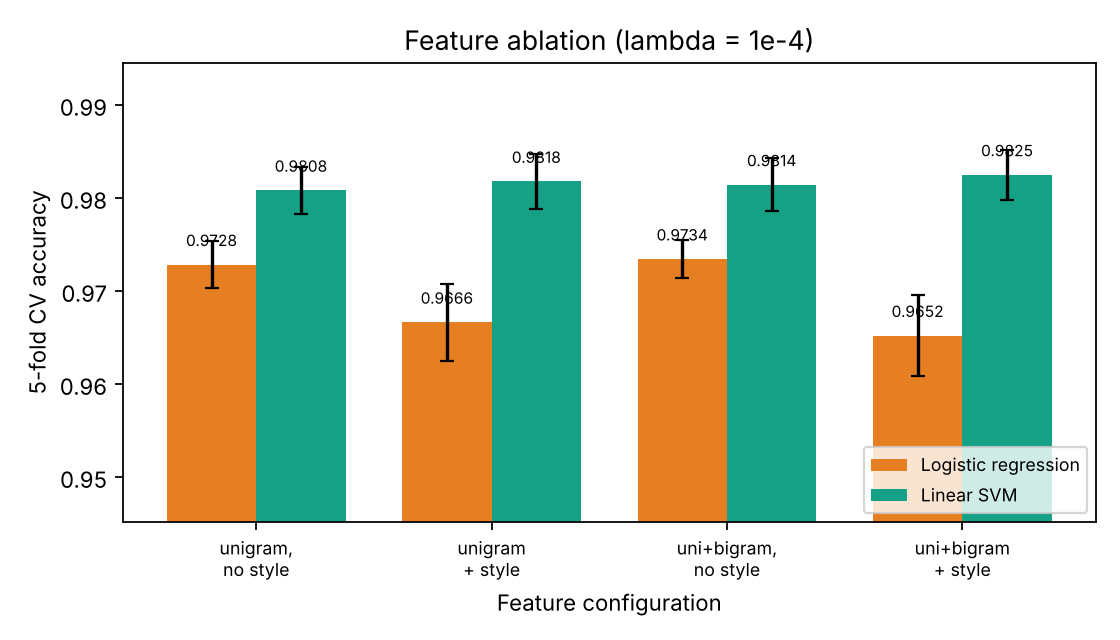

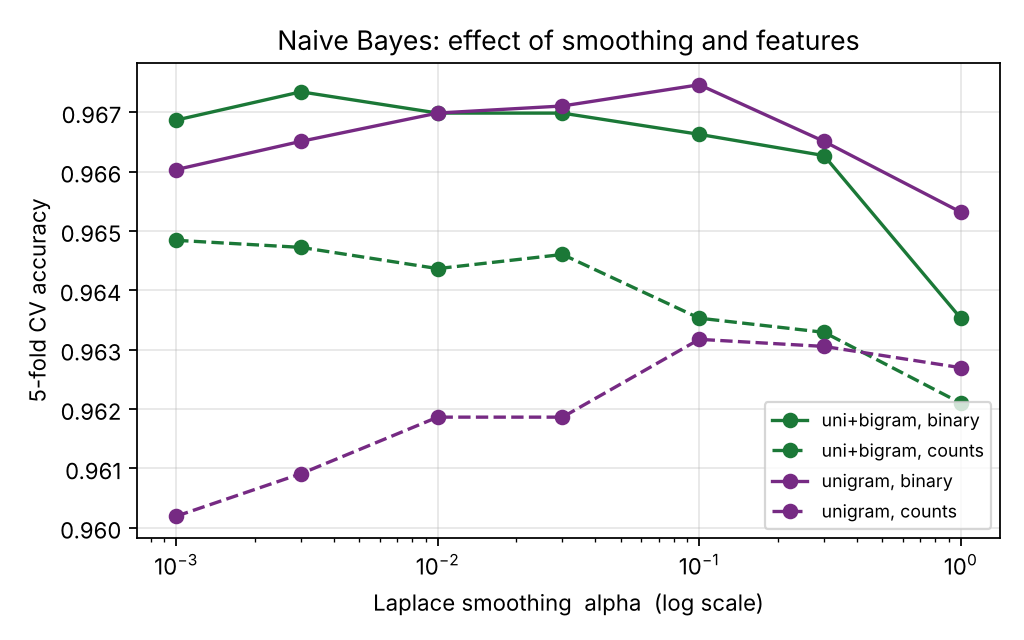

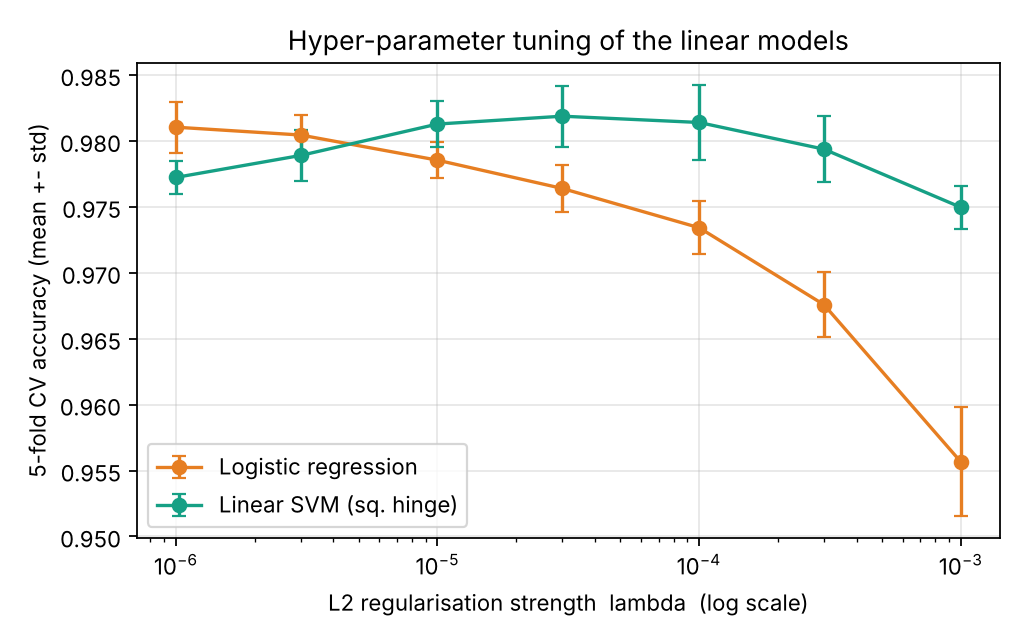

In [8]:
S = E.stage_tune(S)
show('fig6_ablation.png'); show('fig3_nb_alpha.png'); show('fig4_lambda_tuning.png')

### Vocabulary size

Does a smaller (more "generic") vocabulary transfer better to an unseen source? For each size `K` I measure in-domain
validation accuracy and transfer between the two corpora (training pool only).

  K=1000   in-domain 0.9517 | SA->Enron 0.5532 | Enron->SA 0.5645 | mean transfer 0.5589


  K=3000   in-domain 0.9696 | SA->Enron 0.6017 | Enron->SA 0.6051 | mean transfer 0.6034


  K=10000  in-domain 0.9791 | SA->Enron 0.6163 | Enron->SA 0.5506 | mean transfer 0.5835


  K=40000  in-domain 0.9881 | SA->Enron 0.6683 | Enron->SA 0.5427 | mean transfer 0.6055
=> chosen vocabulary size: 40000


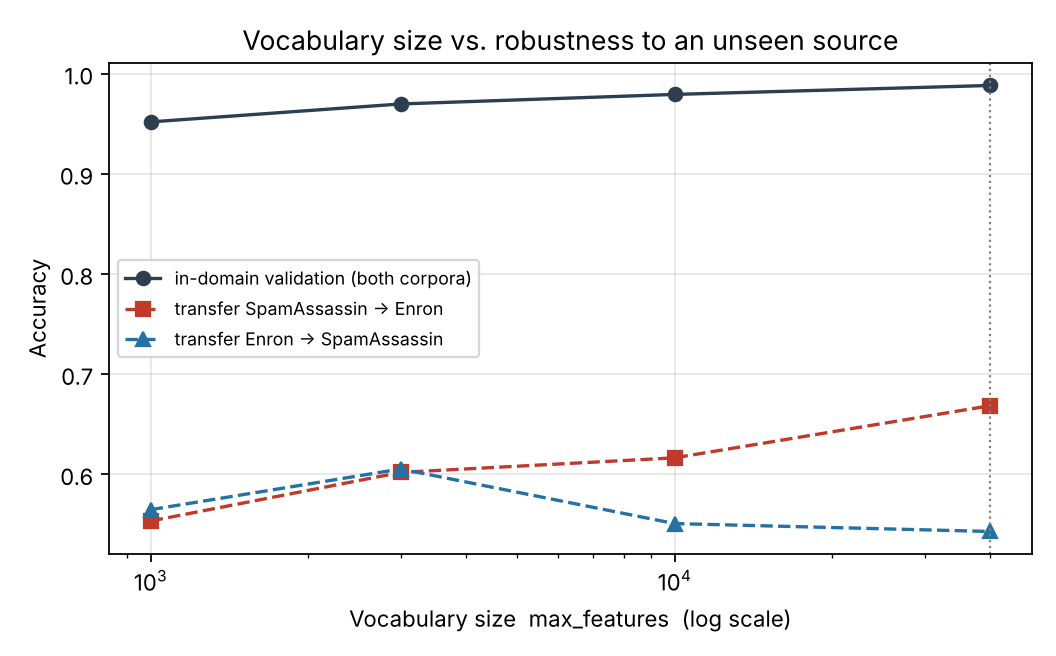

In [9]:
S = E.stage_vocab(S)
show('fig11_vocab.png')

### Cost-sensitive training (`ham_weight`)

For a mail filter, a **false alarm on a legitimate e-mail is worse than a missed spam**, and (Section 7) the dominant error under
distribution shift is exactly "unfamiliar ham flagged as spam". I therefore add a hyper-parameter `ham_weight` w: ham gets w times the
(class-balanced) training weight in LR/SVM and the Naive Bayes prior becomes w/(1+w). Rule: the **largest w whose in-domain accuracy is
within 0.3 pt** of the best (training pool only).

  ham_weight=1    in-domain 0.9881 (FP 5, FN 15) | SA->Enron 0.6683 | Enron->SA 0.5427 | mean transfer 0.6055


  ham_weight=2    in-domain 0.9857 (FP 5, FN 19) | SA->Enron 0.7470 | Enron->SA 0.5803 | mean transfer 0.6637


  ham_weight=4    in-domain 0.9821 (FP 5, FN 25) | SA->Enron 0.7817 | Enron->SA 0.6145 | mean transfer 0.6981


  ham_weight=8    in-domain 0.9791 (FP 4, FN 31) | SA->Enron 0.7949 | Enron->SA 0.6438 | mean transfer 0.7194
=> chosen ham_weight: 2.0


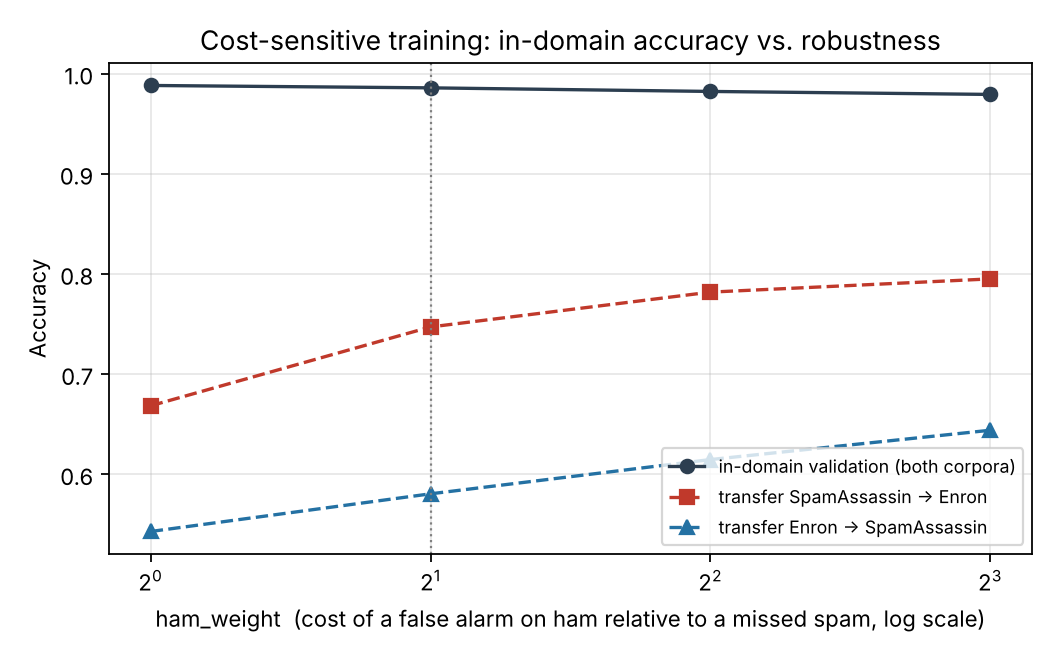

In [10]:
S = E.stage_costs(S)
show('fig13_costs.png')

## 6. Evaluation on the untouched hold-out set

fitted on 8391 e-mails in 10.2s; vocabulary = 40000 terms


  NB    acc=0.9700  prec=0.9754  rec=0.9253  F1=0.9497  (TP=595 FP=15 FN=48 TN=1440)
  LR    acc=0.9800  prec=0.9673  rec=0.9673  F1=0.9673  (TP=622 FP=21 FN=21 TN=1434)
  SVM   acc=0.9809  prec=0.9631  rec=0.9751  F1=0.9691  (TP=627 FP=24 FN=16 TN=1431)
  VOTE  acc=0.9809  prec=0.9674  rec=0.9705  F1=0.9689  (TP=624 FP=21 FN=19 TN=1434)
  hold-out, SpamAssassin only: acc=0.9838  prec=0.9664  rec=0.9801  F1=0.9732  (TP=345 FP=12 FN=7 TN=806)
  hold-out, Enron-1      only: acc=0.9774  prec=0.9688  rec=0.9588  F1=0.9637  (TP=279 FP=9 FN=12 TN=628)


AUC: {'nb': 0.9935, 'lr': 0.9978, 'svm': 0.9977}


final objective LR 0.01895 (relative change over last 50 its: 2.42e-02), SVM 0.01950


Misclassified hold-out e-mails (40):
  true=0 pred=1 [easy-ham-1] The case for spam
  true=0 pred=1 [easy-ham-1] InfoWorld profile of Max Levchin
  true=0 pred=1 [easy-ham-1] Re: K3B
  true=0 pred=1 [easy-ham-2] There will be no Trojan War
  true=0 pred=1 [easy-ham-2] lifegem
  true=0 pred=1 [easy-ham-2] The Evil Gerald Online - World Cup Issue Out Now!
  true=0 pred=1 [hard-ham-1] 日本語の件名（サブジェクト） スパムメールではありません！
  true=0 pred=1 [hard-ham-1] Your NEW "Leg-Up" on Wall Street...
  true=0 pred=1 [hard-ham-1] Cash Flow Doesn't Lie...Even After Today's Rally 
  true=0 pred=1 [hard-ham-1] Cost price Guinness, Budweiser and selected spirits at tesco.ie
  true=0 pred=1 [hard-ham-1] CuteFTP exclusive: OmniPage Pro with DNS
  true=0 pred=1 [hard-ham-1] FC Sporadic for Wednesday, October 30, 2002


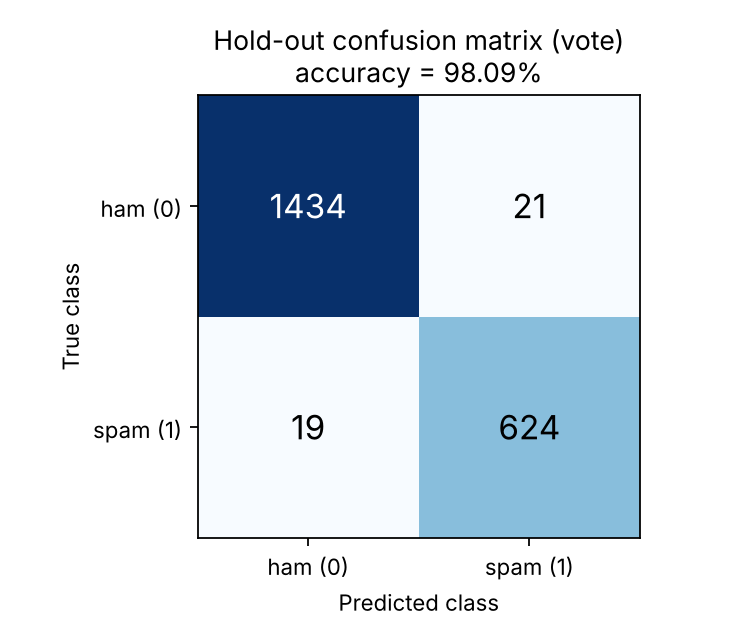

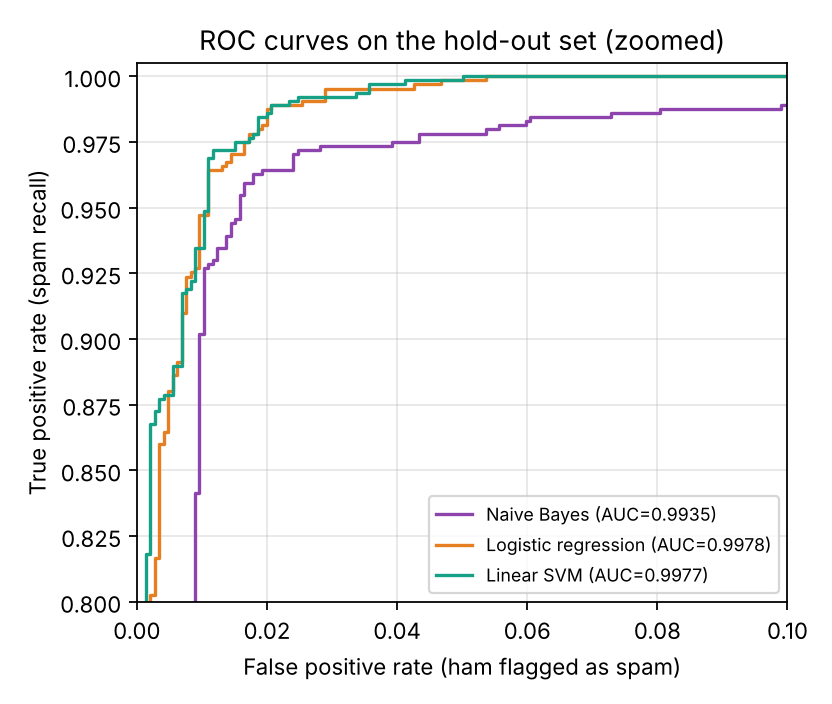

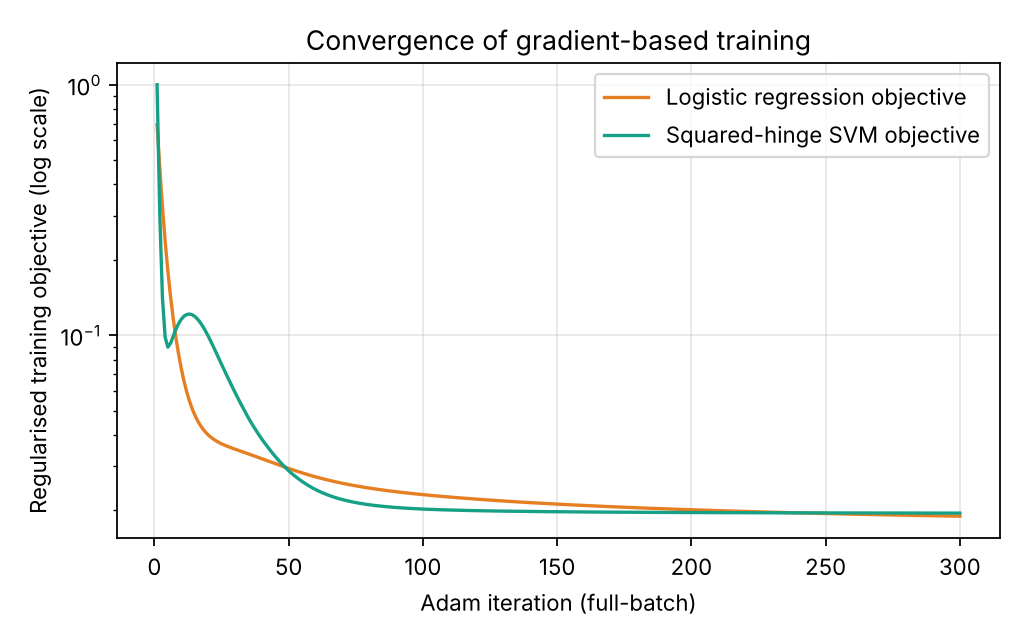

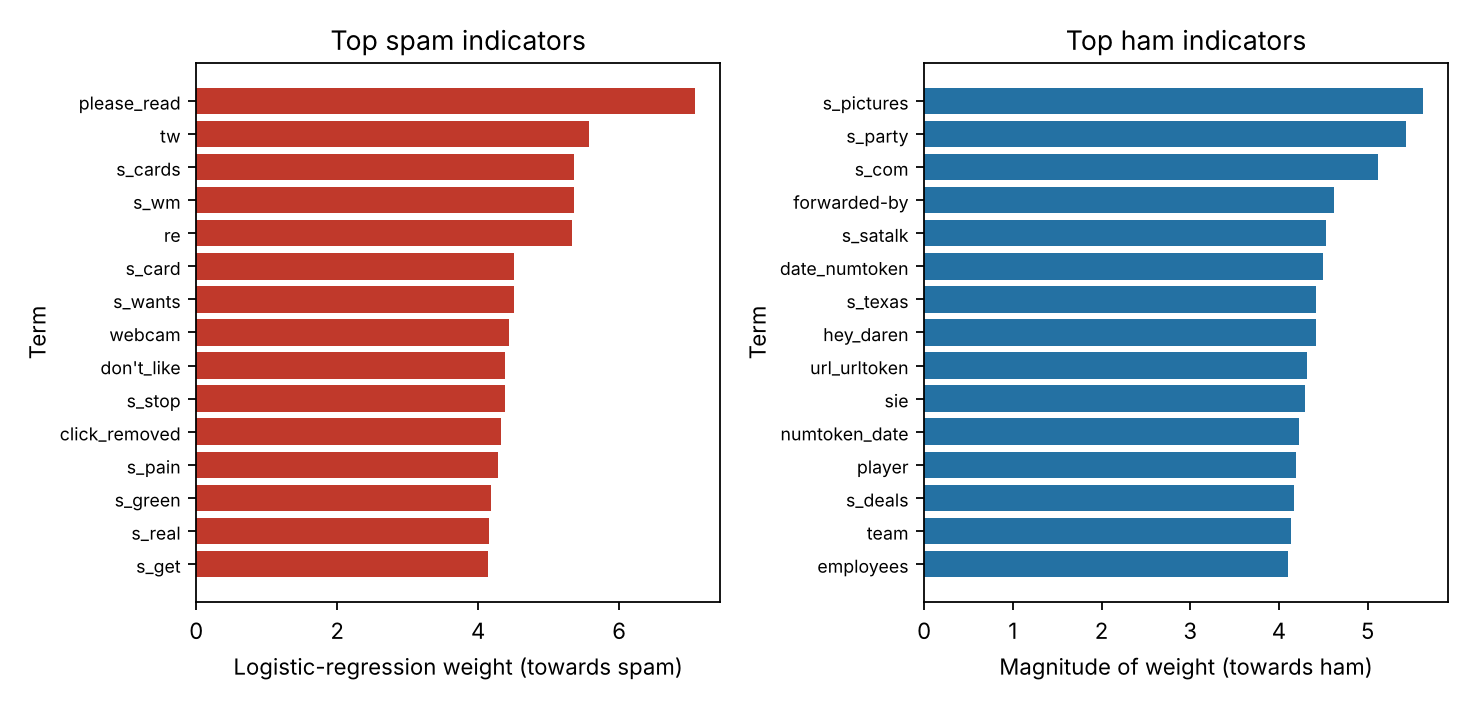

In [11]:
S = E.stage_holdout(S)
show('fig7_confusion.png', 420); show('fig8_roc.png', 480); show('fig5_loss_curves.png'); show('fig9_top_terms.png', 760)

**Reading the results.** The final ensemble reaches **98.09 %** accuracy on the untouched hold-out set (precision 0.967, recall 0.970), similarly on both corpora. Logistic regression and the SVM beat Naive Bayes in-domain. Errors are mostly legitimate newsletters/marketing mail flagged as spam, and short or obfuscated spam let through. The top-weighted logistic-regression terms are idiosyncratic (rare, corpus-specific words) because the selected lambda is tiny; this already hints at the corpus dependence measured next.

## 7. Robustness: what happens when the test e-mails come from somewhere else?

The hold-out set above is drawn from the same corpora as the training data. The real test set may not be, so I ran
four stress tests (hyper-parameters fixed, models retrained on the stated data only):

* **(a) cross-corpus transfer** -- train on SpamAssassin, test on Enron (and vice-versa);
* **(b) temporal shift** inside SpamAssassin -- train on the 2002 `*-1` sets, test on the later-collected `*-2` sets;
* **(c) header-leak check** -- Naive Bayes that sees only transport headers;
* **(d) SMS data** as extra training data -- does it help or hurt e-mail accuracy? (kept only if the hold-out accuracy does not drop by more than 0.25 pt);
* **(e) probe set** -- 24 short hand-written *modern* e-mails (12 spam, 12 ham; folder `test/`) I wrote myself.
  This is tiny and informal; it is a smoke test of domain shift, not an accuracy estimate.

(a) Cross-corpus transfer (train on one corpus, test on the other; hyper-parameters fixed)
   SA->Enron  train 5850 / test 4639
      NB    acc=0.7907  prec=0.7072  rec=0.5677  F1=0.6298  (TP=826 FP=342 FN=629 TN=2842)
      LR    acc=0.7342  prec=0.5669  rec=0.6467  F1=0.6042  (TP=941 FP=719 FN=514 TN=2465)
      SVM   acc=0.6454  prec=0.4569  rec=0.6914  F1=0.5502  (TP=1006 FP=1196 FN=449 TN=1988)
      FINAL acc=0.7338  prec=0.5654  rec=0.6536  F1=0.6063  (TP=951 FP=731 FN=504 TN=2453)
   Enron->SA  train 4639 / test 5850
      NB    acc=0.5258  prec=0.3868  rec=0.9858  F1=0.5556  (TP=1734 FP=2749 FN=25 TN=1342)
      LR    acc=0.6135  prec=0.4347  rec=0.9500  F1=0.5965  (TP=1671 FP=2173 FN=88 TN=1918)
      SVM   acc=0.5593  prec=0.4025  rec=0.9608  F1=0.5673  (TP=1690 FP=2509 FN=69 TN=1582)
      FINAL acc=0.5756  prec=0.4119  rec=0.9619  F1=0.5768  (TP=1692 FP=2416 FN=67 TN=1675)


(b) Temporal shift inside SpamAssassin: train on *-1 subsets (3177), test on later *-2 subsets (2673)
    NB    acc=0.8904  prec=0.9980  rec=0.7737  F1=0.8717  (TP=995 FP=2 FN=291 TN=1385)
    LR    acc=0.9297  prec=0.9991  rec=0.8546  F1=0.9212  (TP=1099 FP=1 FN=187 TN=1386)
    SVM   acc=0.9327  prec=0.9973  rec=0.8624  F1=0.9249  (TP=1109 FP=3 FN=177 TN=1384)
    FINAL acc=0.9270  prec=0.9991  rec=0.8491  F1=0.9180  (TP=1092 FP=1 FN=194 TN=1386)


(c) NB on raw transport headers ONLY: random hold-out acc 0.9701, temporal-shift acc 0.8691


(d) SMS study  [final ensemble]
    trained on e-mail only : e-mail hold-out acc 0.9809 | SMS hold-out acc 0.6297 (spam recall 0.790)
    e-mail + 80% SMS       : e-mail hold-out acc 0.9690 | SMS hold-out acc 0.9892 (spam recall 0.941)
(e) 24 hand-written modern e-mails: e-mail-only model acc 0.875 (wrong: [8, 21, 22]) | +SMS model acc 0.875 (wrong: [8, 21, 22])
=> SMS augmentation for the final model: False


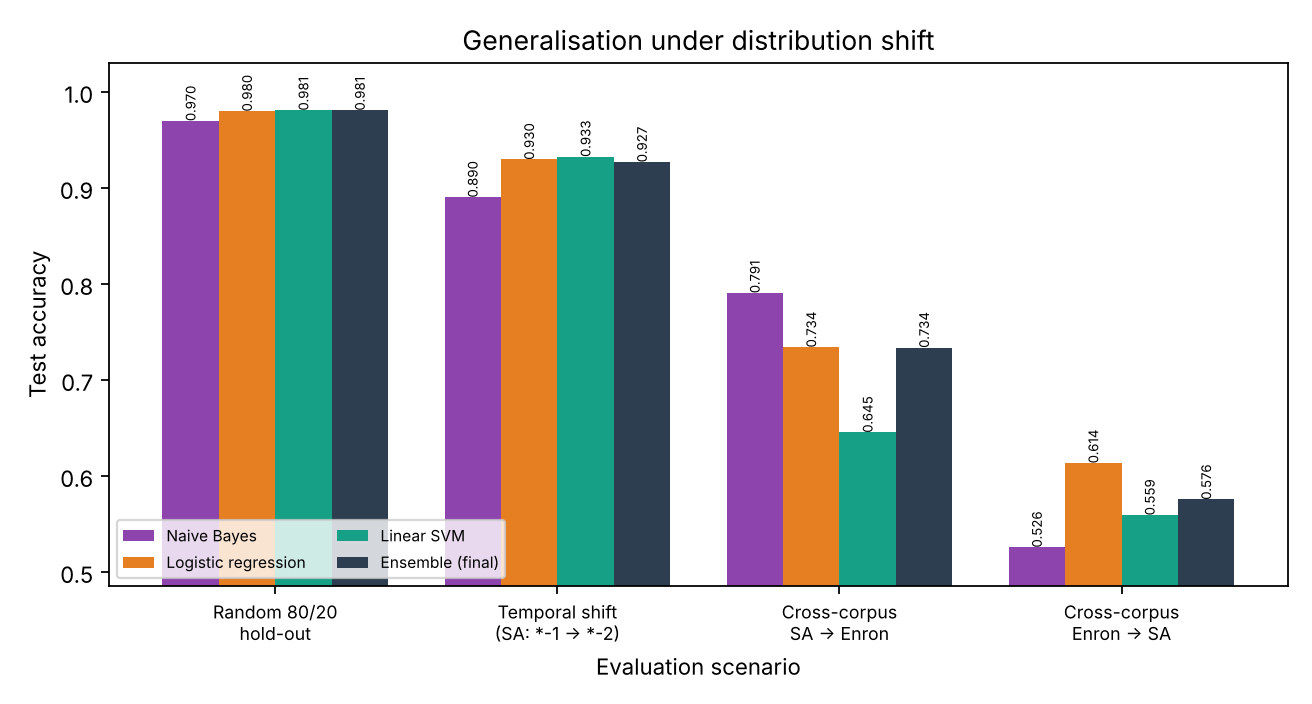

In [12]:
S = E.stage_shift(S)
show('fig10_shift.png', 760)

**Reading the results.** In-domain accuracy overstates what to expect on mail from another source. Training on one corpus and testing on the other gives only 73.4 % (SpamAssassin to Enron) and 57.6 % (Enron to SpamAssassin); a temporal shift inside SpamAssassin gives 92.7 %. Transport headers alone classify well in-corpus but collapse under shift, so they are excluded. SMS data was not used (it reduced e-mail accuracy). The cost factor `ham_weight` trades a little in-domain accuracy for noticeably better transfer.

## 8. Final model and the prediction function

The final model is re-trained on **all** available labelled documents (e-mails of both corpora, plus SMS only if Section 7(d)
approved it) with the selected hyper-parameters and saved to `model/spam_model.npz`. Its training accuracy is *not* a
performance estimate; the estimates are the hold-out and shift experiments above.

In [13]:
S = E.stage_final(S)

final model trained on 10489 documents (e-mails only) in 15.4s; vocabulary 40000; saved /home/claude/spam_project/model/spam_model.npz (1.0 MB)
  (training-set accuracy 0.9996 -- NOT a performance estimate)


In [14]:
# --- the required interface: read every file in ./test and print +1 / 0 ------------------------------
import importlib, classify
importlib.reload(classify)
res = classify.predict_folder('test')
labels = dict(l.strip().split(',') for l in open('test_labels.txt'))
acc = np.mean([int(labels[k]) == v for k, v in res.items()])
print('\naccuracy on the 24-mail demo folder (hand-written, informal): %.3f' % acc)
print('predictions.txt written ->', open('predictions.txt').read().split()[:4], '...')

email1.txt               +1 (spam)
email2.txt                0 (not spam)
email3.txt               +1 (spam)
email4.txt                0 (not spam)
email5.txt               +1 (spam)
email6.txt                0 (not spam)
email7.txt               +1 (spam)
email8.txt               +1 (spam)
email9.txt               +1 (spam)
email10.txt               0 (not spam)
email11.txt              +1 (spam)
email12.txt               0 (not spam)
email13.txt              +1 (spam)
email14.txt               0 (not spam)
email15.txt              +1 (spam)
email16.txt               0 (not spam)
email17.txt              +1 (spam)
email18.txt               0 (not spam)
email19.txt              +1 (spam)
email20.txt               0 (not spam)
email21.txt               0 (not spam)
email22.txt              +1 (spam)
email23.txt              +1 (spam)
email24.txt               0 (not spam)
-> 24 e-mails: 13 spam, 11 not spam

accuracy on the 24-mail demo folder (hand-written, informal): 0.875
predictions

In [15]:
R = json.load(open('results/results.json'))
print('SUMMARY')
print('  corpus: %d e-mails (%d spam)   hold-out accuracy (final ensemble): %.4f' % (R['n_docs'], R['n_spam'], R['holdout_final']['acc']))
for n, v in R['holdout_src'].items():
    print('     hold-out accuracy on %-13s: %.4f' % (n, v['acc']))
print('  cross-corpus accuracy  SA->Enron: %.3f   Enron->SA: %.3f' % (
    R['shift']['cross']['SA->Enron']['results']['final']['acc'], R['shift']['cross']['Enron->SA']['results']['final']['acc']))
print('  temporal-shift accuracy: %.3f' % R['shift']['temporal']['results']['final']['acc'])
print('  hyper-parameters:', json.dumps(R['hp']))

SUMMARY
  corpus: 10489 e-mails (3214 spam)   hold-out accuracy (final ensemble): 0.9809
     hold-out accuracy on SpamAssassin : 0.9838
     hold-out accuracy on Enron-1      : 0.9774
  cross-corpus accuracy  SA->Enron: 0.734   Enron->SA: 0.576
  temporal-shift accuracy: 0.927
  hyper-parameters: {"ngram": 2, "min_df": 3, "max_features": 40000, "style_scale": 0.0, "nb_alpha": 0.003, "nb_binary": true, "lr_lambda": 1e-06, "svm_lambda": 3e-05, "n_iter": 300, "lr": 0.1, "rule": "vote", "ham_weight": 2.0}


## Conclusions and limitations

* A from-scratch ensemble (Naive Bayes + logistic regression + linear SVM on TF-IDF uni/bigrams of subject and body) gives **98.09 %** hold-out accuracy.
* Hyper-parameters were chosen by stratified 5-fold CV on the training pool only; kernel choice (linear) is supported by `kernel_check.py`.
* The main weakness is **domain shift**: training data are public corpora from 2000-2003, so accuracy on e-mails from a different source or era will be noticeably lower than the hold-out figure. More diverse training data is the real remedy.
* Prediction: `classify.predict_folder('test')` prints +1 / 0 for every file in `test/`.